Ghi chú ngày 3: học linear regression
## Linear Regression


In [ ]:
# 0 — Import thư viện
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression          # chỉ để đối chiếu
from sklearn import metrics as skm                          # chỉ để đối chiếu

np.set_printoptions(precision=6, suppress=True)

## Bài 1 — Dữ liệu giả lập

In [2]:
# 1.1 — Sinh dữ liệu: y = 3x + 4 + noise
np.random.seed(42)
n = 200
x = np.random.uniform(0, 10, n)
noise = np.random.normal(0, 2, n)
y = 3 * x + 4 + noise

X = x.reshape(-1, 1)        # (200, 1)
print(X.shape, y.shape)

(200, 1) (200,)


In [3]:
# 1.2 — Hàm add_bias
def add_bias(X):
    """Thêm cột 1 vào đầu: (n, d) -> (n, d+1)."""
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    return np.hstack([np.ones((X.shape[0], 1)), X])

Xb = add_bias(X)
print(Xb[:3])

[[1.       3.745401]
 [1.       9.507143]
 [1.       7.319939]]


In [4]:
# 1.3 — fit_normal_equation bằng np.linalg.lstsq
def fit_normal_equation(X, y):
    """Giải min ||Xw - y||^2. X đã có cột bias."""
    w, *_ = np.linalg.lstsq(X, y, rcond=None)
    return w

w = fit_normal_equation(Xb, y)
print("w ước lượng :", w)
print("w thật      :", np.array([4.0, 3.0]))
print("sai khác    :", w - np.array([4.0, 3.0]))

w ước lượng : [4.210402 2.984386]
w thật      : [4. 3.]
sai khác    : [ 0.210402 -0.015614]


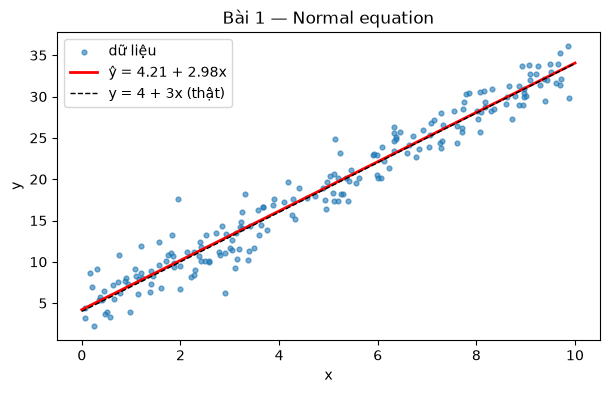

In [5]:
# 1.4 — Vẽ scatter và đường dự đoán
x_line = np.linspace(0, 10, 100)
y_line = add_bias(x_line) @ w

plt.figure(figsize=(7, 4))
plt.scatter(x, y, s=12, alpha=0.6, label="dữ liệu")
plt.plot(x_line, y_line, "r", lw=2, label=f"ŷ = {w[0]:.2f} + {w[1]:.2f}x")
plt.plot(x_line, 3 * x_line + 4, "k--", lw=1, label="y = 4 + 3x (thật)")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.title("Bài 1 — Normal equation")
plt.show()

In [6]:
# 1.5 — Kiểm tra tính chất hình học: X^T (y - Xw) ≈ 0
residual = y - Xb @ w
ortho = Xb.T @ residual
print("X^T (y - Xw) =", ortho)
print("≈ 0 ?", np.allclose(ortho, 0, atol=1e-8))

X^T (y - Xw) = [0. 0.]
≈ 0 ? True


**Nhận xét 1.5:** phần dư vuông góc với không gian cột của X, tức ŷ là hình chiếu trực giao của y lên col(X). Hàng đầu tiên ứng với cột bias, nên tổng phần dư cũng bằng 0.

## Bài 2 — California Housing

In [7]:
# 2.1 — Tải dữ liệu
data = fetch_california_housing()
X_house, y_house = data.data, data.target
feature_names = data.feature_names
print(X_house.shape, y_house.shape)
print(feature_names)

(20640, 8) (20640,)
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [8]:
# 2.2 — Chia train/test 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X_house, y_house, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(16512, 8) (4128, 8)


In [9]:
# 2.3 — class LinearRegressionNE
class LinearRegressionNE:
    def fit(self, X, y):
        Xb = add_bias(X)
        w = fit_normal_equation(Xb, y)
        self.intercept_ = w[0]
        self.coef_ = w[1:]
        return self

    def predict(self, X):
        return np.asarray(X) @ self.coef_ + self.intercept_

my_lr = LinearRegressionNE().fit(X_train, y_train)
print("intercept_:", my_lr.intercept_)
print("coef_     :", my_lr.coef_)

intercept_: -37.02327770606412
coef_     : [ 0.448675  0.009724 -0.123323  0.783145 -0.000002 -0.003526 -0.419792
 -0.433708]


In [10]:
# 2.4 — Đối chiếu với sklearn LinearRegression
sk_lr = LinearRegression().fit(X_train, y_train)

diff_coef = np.max(np.abs(my_lr.coef_ - sk_lr.coef_))
diff_inter = abs(my_lr.intercept_ - sk_lr.intercept_)
print(f"max |Δcoef|  = {diff_coef:.2e}")
print(f"|Δintercept| = {diff_inter:.2e}")
assert diff_coef < 1e-6 and diff_inter < 1e-6, "Sai khác quá lớn!"
print("OK — khớp sklearn")

max |Δcoef|  = 1.10e-14
|Δintercept| = 1.49e-13
OK — khớp sklearn


## Bài 3 — Tự viết metric

In [11]:
# 3.1 — mse, rmse, mae, r2 bằng NumPy
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return 1 - ss_res / ss_tot

In [12]:
# 3.2 — Tính trên tập test và đối chiếu sklearn.metrics
y_pred = my_lr.predict(X_test)

ours = {"MSE": mse(y_test, y_pred), "RMSE": rmse(y_test, y_pred),
        "MAE": mae(y_test, y_pred), "R2": r2(y_test, y_pred)}
theirs = {"MSE": skm.mean_squared_error(y_test, y_pred),
          "RMSE": np.sqrt(skm.mean_squared_error(y_test, y_pred)),
          "MAE": skm.mean_absolute_error(y_test, y_pred),
          "R2": skm.r2_score(y_test, y_pred)}

for k in ours:
    print(f"{k:5s} ours={ours[k]:.6f}  sklearn={theirs[k]:.6f}  Δ={abs(ours[k]-theirs[k]):.1e}")

MSE   ours=0.555892  sklearn=0.555892  Δ=0.0e+00
RMSE  ours=0.745581  sklearn=0.745581  Δ=0.0e+00
MAE   ours=0.533200  sklearn=0.533200  Δ=0.0e+00
R2    ours=0.575788  sklearn=0.575788  Δ=0.0e+00


In [13]:
# 3.3 — R² của "mô hình" luôn đoán y_train.mean()
baseline = np.full_like(y_test, y_train.mean())
print("R² baseline (test) :", r2(y_test, baseline))
print("R² baseline (train):", r2(y_train, np.full_like(y_train, y_train.mean())))

R² baseline (test) : -0.00021908714592466794
R² baseline (train): 0.0


**Nhận xét 3.3:** R² = 1 − SS_res/SS_tot. Nếu đoán đúng mean của chính tập đang đánh giá thì SS_res = SS_tot, nên R² = 0 chính xác (đây là trường hợp tập train). Trên tập test, ta dùng mean của *train* chứ không phải mean của test, nên R² hơi âm và gần 0. Kết quả này đúng lý thuyết: R² = 0 nghĩa là "không hơn đoán trung bình", còn R² < 0 nghĩa là tệ hơn cả mức đó.

## Bài 4 — Chuẩn hóa và diễn giải

In [14]:
# 4.1 — StandardScaler tự viết
class MyStandardScaler:
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)          # ddof=0 giống sklearn
        self.scale_[self.scale_ == 0] = 1.0  # tránh chia 0
        return self

    def transform(self, X):
        return (X - self.mean_) / self.scale_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

scaler = MyStandardScaler().fit(X_train)     # CHỈ fit trên train
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)
print("mean train sau scale ≈ 0:", X_train_s.mean(axis=0).round(6))
print("std  train sau scale ≈ 1:", X_train_s.std(axis=0).round(6))

mean train sau scale ≈ 0: [-0. -0.  0. -0. -0. -0.  0. -0.]
std  train sau scale ≈ 1: [1. 1. 1. 1. 1. 1. 1. 1.]


In [15]:
# 4.2 — Train lại trên dữ liệu chuẩn hóa, so sánh RMSE và hệ số
lr_s = LinearRegressionNE().fit(X_train_s, y_train)

print("RMSE gốc    :", rmse(y_test, my_lr.predict(X_test)))
print("RMSE scaled :", rmse(y_test, lr_s.predict(X_test_s)))

print(f"\n{'feature':12s}{'w gốc':>12s}{'w scaled':>12s}{'w gốc*std':>12s}")
for name, w0, ws, sd in zip(feature_names, my_lr.coef_, lr_s.coef_, scaler.scale_):
    print(f"{name:12s}{w0:12.4f}{ws:12.4f}{w0*sd:12.4f}")
print("\nintercept scaled =", lr_s.intercept_, " | y_train.mean() =", y_train.mean())

RMSE gốc    : 0.7455813830127748
RMSE scaled : 0.7455813830127761

feature            w gốc    w scaled   w gốc*std
MedInc            0.4487      0.8544      0.8544
HouseAge          0.0097      0.1225      0.1225
AveRooms         -0.1233     -0.2944     -0.2944
AveBedrms         0.7831      0.3393      0.3393
Population       -0.0000     -0.0023     -0.0023
AveOccup         -0.0035     -0.0408     -0.0408
Latitude         -0.4198     -0.8969     -0.8969
Longitude        -0.4337     -0.8698     -0.8698

intercept scaled = 2.071946937378617  | y_train.mean() = 2.071946937378876


**Nhận xét 4.2:** RMSE giữ nguyên, vì chuẩn hóa là phép biến đổi affine của X: không gian cột không đổi nên hình chiếu không đổi. Chỉ có hệ số thay đổi theo công thức `w_scaled = w_gốc × std`, còn intercept trở thành `y_train.mean()`. Sau khi chuẩn hóa, các hệ số so sánh trực tiếp được với nhau (mức thay đổi của y khi đặc trưng tăng 1 độ lệch chuẩn).

In [16]:
# 4.3 — Top 3 đặc trưng có |w| lớn nhất + tương quan AveRooms/AveBedrms
order = np.argsort(-np.abs(lr_s.coef_))
print("Top 3 đặc trưng theo |w| (đã chuẩn hóa):")
for i in order[:3]:
    print(f"  {feature_names[i]:12s} w = {lr_s.coef_[i]:+.4f}")

i_r, i_b = feature_names.index("AveRooms"), feature_names.index("AveBedrms")
print("\nw AveRooms  =", lr_s.coef_[i_r])
print("w AveBedrms =", lr_s.coef_[i_b])
print("corr(AveRooms, AveBedrms) =", np.corrcoef(X_train[:, i_r], X_train[:, i_b])[0, 1])

Top 3 đặc trưng theo |w| (đã chuẩn hóa):
  Latitude     w = -0.8969
  Longitude    w = -0.8698
  MedInc       w = +0.8544

w AveRooms  = -0.29441013447329983
w AveBedrms = 0.3392594905944839
corr(AveRooms, AveBedrms) = 0.8361628587348408


**Nhận xét 4.3** (dự kiến, đối chiếu lại với output thực tế):
- **Latitude** và **Longitude** mang hệ số âm lớn do yếu tố vị trí: càng lên phía bắc hoặc vào sâu trong đất liền thì giá càng giảm. Hai biến này cùng nhau mã hóa các vùng ven biển đắt đỏ.
- **MedInc** mang hệ số dương lớn: thu nhập khu vực càng cao thì giá nhà càng cao.
- **Ngược trực giác:** AveRooms có hệ số **âm**, còn AveBedrms có hệ số **dương**. Hai biến tương quan mạnh nên có **đa cộng tuyến**. Hệ số AveRooms nên hiểu là "giữ AveBedrms cố định mà tăng số phòng". Không nên diễn giải từng hệ số riêng lẻ khi các biến tương quan cao.

## Bài 5 — Polynomial features

In [17]:
# 5.1 — Sinh dữ liệu y = 0.5x² − x + 2 + noise, x ∈ [−3, 3]
np.random.seed(42)
n5 = 40
x5 = np.random.uniform(-3, 3, n5)
y5 = 0.5 * x5**2 - x5 + 2 + np.random.normal(0, 1, n5)

def poly_features(x, degree):
    """[x, x^2, ..., x^degree] — chưa có bias."""
    return np.column_stack([x**k for k in range(1, degree + 1)])

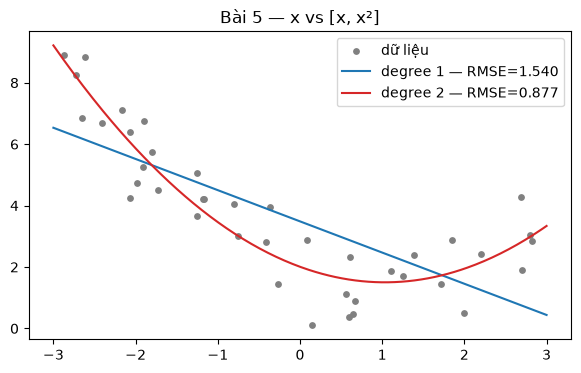

In [18]:
# 5.2 — Fit với x và với [x, x²], vẽ và so sánh RMSE
x_plot = np.linspace(-3, 3, 300)

plt.figure(figsize=(7, 4))
plt.scatter(x5, y5, s=15, c="gray", label="dữ liệu")
for deg, color in [(1, "tab:blue"), (2, "tab:red")]:
    m = LinearRegressionNE().fit(poly_features(x5, deg), y5)
    r = rmse(y5, m.predict(poly_features(x5, deg)))
    plt.plot(x_plot, m.predict(poly_features(x_plot, deg)), color=color,
             label=f"degree {deg} — RMSE={r:.3f}")
plt.legend(); plt.title("Bài 5 — x vs [x, x²]"); plt.show()

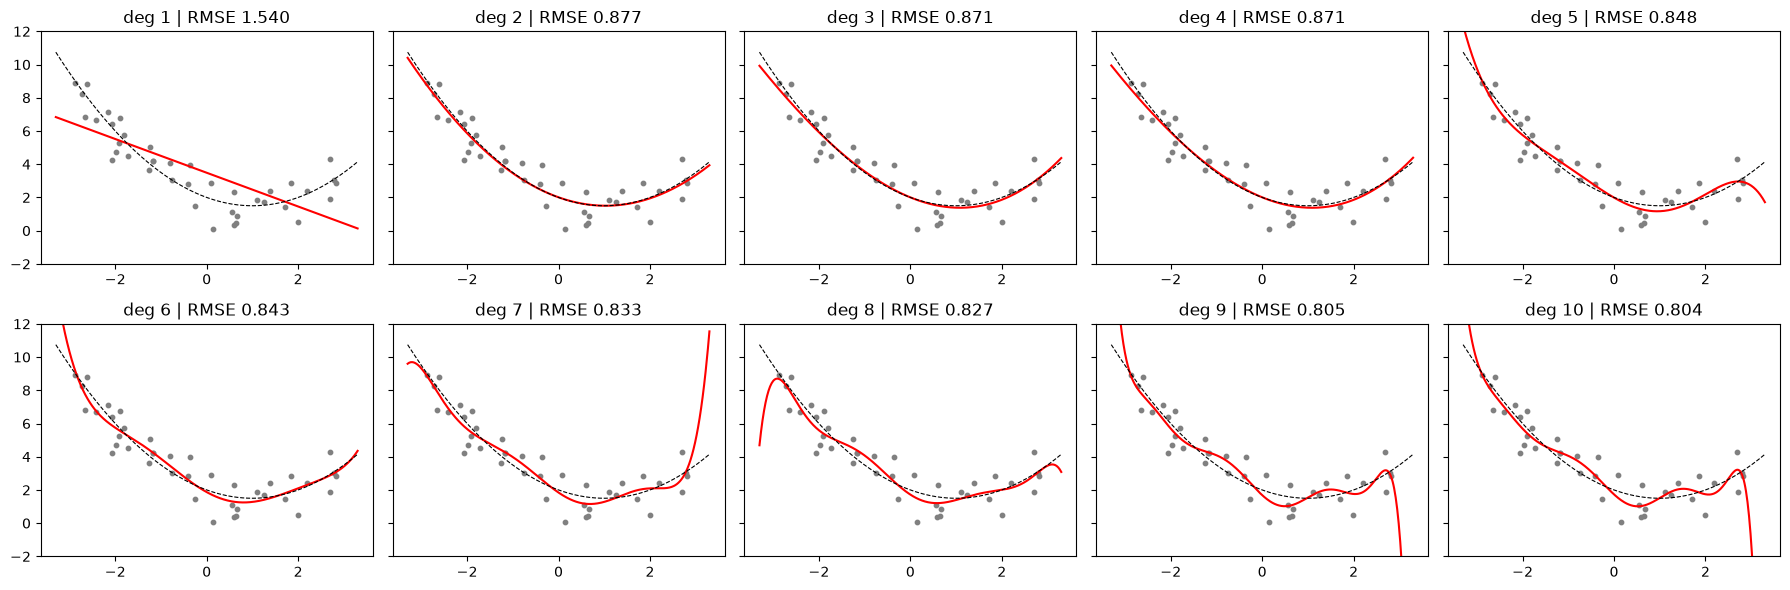

degree  1: train RMSE = 1.5405
degree  2: train RMSE = 0.8770
degree  3: train RMSE = 0.8711
degree  4: train RMSE = 0.8711
degree  5: train RMSE = 0.8482
degree  6: train RMSE = 0.8433
degree  7: train RMSE = 0.8326
degree  8: train RMSE = 0.8271
degree  9: train RMSE = 0.8049
degree 10: train RMSE = 0.8044


In [19]:
# 5.3 — Thử degree 1 → 10, quan sát hai đầu khoảng
x_plot_wide = np.linspace(-3.3, 3.3, 400)    # nhìn hơi ra ngoài 2 đầu
degrees = range(1, 11)
train_rmse = []

fig, axes = plt.subplots(2, 5, figsize=(18, 6), sharey=True)
for deg, ax in zip(degrees, axes.ravel()):
    m = LinearRegressionNE().fit(poly_features(x5, deg), y5)
    train_rmse.append(rmse(y5, m.predict(poly_features(x5, deg))))
    ax.scatter(x5, y5, s=10, c="gray")
    ax.plot(x_plot_wide, m.predict(poly_features(x_plot_wide, deg)), "r")
    ax.plot(x_plot_wide, 0.5*x_plot_wide**2 - x_plot_wide + 2, "k--", lw=0.8)
    ax.set_title(f"deg {deg} | RMSE {train_rmse[-1]:.3f}")
    ax.set_ylim(-2, 12)
plt.tight_layout(); plt.show()

for d, r in zip(degrees, train_rmse):
    print(f"degree {d:2d}: train RMSE = {r:.4f}")

**Nhận xét 5.3:** RMSE trên train không bao giờ tăng khi tăng bậc, vì mô hình bậc cao chứa mô hình bậc thấp. Ở bậc cao, đường cong uốn lượn và **vọt mạnh ở hai đầu khoảng**, nơi có ít dữ liệu. Mô hình đang học thuộc nhiễu, tức là **overfitting** (sẽ học ở tuần 2).

## Bài 6 — Phân tích phần dư (nâng cao)

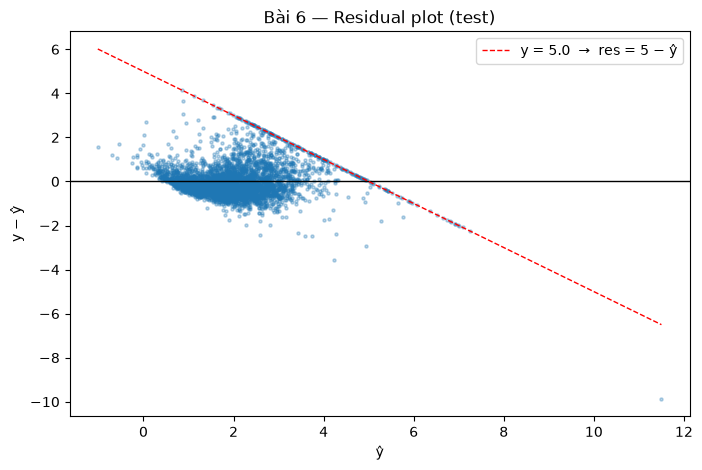

Số điểm y_test >= 5.0: 184 / 4128


In [20]:
# 6.1 — Residual plot cho California Housing (test)
y_hat = my_lr.predict(X_test)
res = y_test - y_hat

plt.figure(figsize=(8, 5))
plt.scatter(y_hat, res, s=5, alpha=0.3)
plt.axhline(0, color="k", lw=1)

# đường lý thuyết cho các điểm bị chặn y = 5.0: res = 5 - ŷ
yy = np.linspace(y_hat.min(), y_hat.max(), 100)
plt.plot(yy, 5.0 - yy, "r--", lw=1, label="y = 5.0  →  res = 5 − ŷ")
plt.xlabel("ŷ"); plt.ylabel("y − ŷ"); plt.legend()
plt.title("Bài 6 — Residual plot (test)")
plt.show()

print("Số điểm y_test >= 5.0:", np.sum(y_test >= 5.0), "/", len(y_test))

In [21]:
# 6.2 — So sánh phần dư nhóm bị chặn và không bị chặn
capped = y_test >= 5.0
print("Mean residual (tất cả)     :", res.mean())
print("Mean residual (y bị chặn)  :", res[capped].mean())
print("Mean residual (không chặn) :", res[~capped].mean())

Mean residual (tất cả)     : 0.0034792979038511507
Mean residual (y bị chặn)  : 1.1529154012723468
Mean residual (không chặn) : -0.05014551016405027


**Nhận xét 6:**
- Phần dư **không phân bố đều** quanh 0: có dạng phễu (heteroscedasticity), và một số ŷ âm hoặc quá lớn vì mô hình tuyến tính không biết giá nhà bị giới hạn.
- **Đường chéo ở góc trên** đến từ việc target bị **chặn ở 5.0**. Mọi căn đắt hơn đều được ghi là 5.0, nên với các điểm này `res = 5 − ŷ`, một đường thẳng có hệ số góc −1.
- Hướng xử lý: bỏ các điểm bị chặn, dùng log(y), hoặc dùng mô hình phi tuyến.